# Is there an interval optimum when the storage time is not fixed in advance?

`06` sweeps τ with the total time held fixed, which forces `R = TOTAL_IDLE / τ`. **τ and R are
then not independent**, and its section 6b shows what that costs: double the experiment and
the apparent optimum doubles with it, τ=24 → τ=48, both at R=4. The minimum tracks the round
count, so `06` cannot answer the question it asks.

This notebook removes the coupling: **fix R, sweep τ**. The experiment length `T = R·τ` then
varies, so the score has to be a rate rather than a total.

## The objective

**What the paper scores.** Eq. (4) of the paper uses `R = pL / T`, the logical error rate per
unit time. It is meant to belong to the interval τ, not to the length of the experiment, and
it does so only when `pL` grows linearly with the number of rounds — hence the paper's
conditions `pL ≪ 1` and `T/Δt = O(d)`.

**Why `pL` stops growing linearly.** The logical qubit is a bit the decoder occasionally gets
wrong, and each failure flips it. Two failures cancel, three look like one: `pL` is the
probability of an **odd number** of logical flips, not the number of flips. So it levels off
at 1/2 however long the memory is stored.

**The model.** Let logical flips arrive independently at a constant rate Γ per unit time (a
Poisson process). The probability of `k` flips in time `T` is `e^(−ΓT)(ΓT)^k / k!`, and summing
over odd `k`:

```
pL = e^(−ΓT)·sinh(ΓT) = (1 − e^(−2ΓT)) / 2        ⟹        Γ = −ln(1 − 2·pL) / (2T)
```

The discrete form is the one `04` already uses to invert flip rates into operation counts:
with a flip probability `q` per round, `pL = (1 − (1 − 2q)^N) / 2` after `N` rounds.

**Why Γ rather than `pL / T`.**

- For `pL ≪ 1`, `Γ ≈ pL / T`: in the paper's own regime the two are the same quantity.
- Toward `pL → 0.5` they come apart. `pL / T` is bounded above by `0.5 / T`, so it falls as
  `T` grows *whether or not the code survived*. Γ undoes the mod-2 cancellation and keeps
  reporting the underlying flip rate, which diverges as the code fails.
- This design fixes R and sweeps τ, so `T = R·τ` grows with τ and the large-τ points are
  exactly the ones that approach 1/2. Scored on `pL / T`, the optimum drifts to the largest τ
  tried; scored on Γ, the score stays comparable across `T`, so its minimum belongs to τ.

**Assumptions and limits.** Logical flips are taken as memoryless at a constant rate. That is
reasonable after a few rounds; the first round and the final destructive readout are slightly
different. **Γ is undefined once `pL` is within 3σ of 0.5**: there `1 − 2·pL` is consistent
with zero and the logarithm reports sampling noise. Those points are marked `sat` and
excluded rather than minimised over.

## Why d = 5 is the main case

A d=3 code corrects one fault per interval, a d=5 code two, so d=5 leaves more room between
"interval long enough to be efficient" and "interval long enough to break the code". That
room shows up as a lower operating point, not as the existence of the effect: section 3 finds
an interior minimum at **both** distances, with `pL` at the minimum 2.7× lower at d=5
(0.039 against 0.108). An earlier version of this section claimed d=3 could not show the
optimum at all; section 3 contradicts that.

| section | question |
| --- | --- |
| 1 | is there an interior minimum in Γ at d=5? |
| 2 | is it a property of the interval — does it survive changing R and `p_1q`? |
| 3 | how does d=3 compare? |

## 0. Setup

In [1]:
# ---- the knobs -------------------------------------------------------------
CODE      = "rotated"
DISTANCE  = 5          # d=3 is run alongside in section 3, as the contrast
R_MAIN    = 8          # rounds, held fixed. Above the R >= d floor.
TAUS      = [1, 2, 4, 6, 8, 10, 12, 14, 16, 20, 24, 32, 48, 64, 96]
P_1Q      = 0.001
P_2Q      = 0.0
P_MEAS    = 0.002
SHOTS     = 6000
REPLICAS  = 2

# controls run on a coarser grid
R_ALT      = 16
P_1Q_ALT   = 0.002
TAUS_CTRL  = [4, 8, 12, 16, 24, 32, 48]
# ----------------------------------------------------------------------------

%matplotlib inline
import pathlib, time
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import sys; sys.path.insert(0, '../src')   # qec_timing.circuit_level
from qec_timing.circuit_level import runcache
from qec_timing.circuit_level import surface_memory as sm

BLUE, ORANGE, AQUA = '#2a78d6', '#eb6834', '#1baf7a'
GRAY, INK, MUTED = '#8a8a86', '#0b0b0b', '#52514e'
plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#c9c9c4', 'axes.labelcolor': MUTED, 'axes.titlesize': 12,
    'axes.labelsize': 11, 'xtick.color': MUTED, 'ytick.color': MUTED,
    'xtick.labelsize': 10, 'ytick.labelsize': 10, 'grid.color': '#e6e6e1',
    'legend.frameon': False, 'legend.fontsize': 10, 'font.size': 11, 'text.color': INK,
})
FIGDIR = pathlib.Path('figures'); FIGDIR.mkdir(exist_ok=True)


def finish(fig, name):
    if not fig.get_constrained_layout():
        fig.tight_layout()
    fig.savefig(FIGDIR / f'{name}.png', bbox_inches='tight', facecolor='white')
    plt.show()


GEOM = {}


def geom(code, d):
    if (code, d) not in GEOM:
        GEOM[(code, d)] = sm.Geometry(code, d)
    return GEOM[(code, d)]


G = geom(CODE, DISTANCE)
corr = (DISTANCE - 1) // 2
print(f"{CODE} d={DISTANCE}: {G.n_data} data + {G.n_anc} ancilla = "
      f"{G.n_data + G.n_anc} qubits")
print(f"measured extraction cost n_data = {G.ops_mean:.3f} charged ops per data qubit/round")
print(f"corrects {corr} fault(s) per interval")
print()
print(runcache.summary())

rotated d=5: 25 data + 24 ancilla = 49 qubits
measured extraction cost n_data = 8.398 charged ops per data qubit/round
corrects 2 fault(s) per interval

/home/harshit-verma/Desktop/Quanti/noise_qec/data  (845 cached runs -- 04_surface_extraction: 60, 04c_extraction_cost_p2q: 56, 06_selene_interval: 352, 07_memory_error_rate: 197, stim_memory: 180)


## 1. Does Γ have an interior minimum?

R fixed, τ swept. Three regimes are expected and all three should be visible:

- **small τ** — many rounds per unit of storage, so extraction damage dominates. `pL` is
  nearly flat here because the extraction cost `R · n_data` does not depend on τ, so
  `Γ ≈ const/τ` and simply falls.
- **the turn** — idle faults per interval approach what the code can absorb.
- **large τ** — the code starts failing and Γ rises.

`pL` is reported alongside and should rise monotonically: more stored time, more error. It
has no optimum of its own, which is the point — `Γ` is what carries the answer.

In [2]:
EXPERIMENT = '07_memory_error_rate'


def logical_error(code, d, tau, rounds, shots=SHOTS, replicas=REPLICAS,
                  p_1q=P_1Q, p_2q=P_2Q, p_meas=P_MEAS):
    """Pooled (pL, sigma) over independent replicas, cached per replica."""
    g = geom(code, d)
    F = N = 0
    for k in range(replicas):
        params = dict(code=code, distance=d, tau=tau, rounds=rounds, shots=shots,
                      shot_offset=k * shots, p_1q=p_1q, p_2q=p_2q, p_meas=p_meas,
                      decoder='pymatching', priors='measured-per-qubit')
        hit = runcache.load(EXPERIMENT, params)
        if hit is None:
            fails = g.failures(tau, rounds, shots, offset=k * shots,
                               p_1q=p_1q, p_2q=p_2q, p_meas=p_meas)
            hit = {'failures': int(fails), 'shots': int(shots), 'pL': fails / shots}
            runcache.save(EXPERIMENT, params, hit)
        F += hit['failures']; N += hit['shots']
    e = F / N
    return e, float(np.sqrt(max(e * (1 - e), 1e-12) / N))


def decay_rate(pL, sigma, T):
    """Gamma and its error, from pL = (1 - exp(-2*Gamma*T))/2.

    Undefined within 3 sigma of a coin flip: there 1 - 2*pL is consistent with zero and
    the logarithm reports noise.

    dGamma/dpL = 1 / ((1 - 2*pL) * T), so the error propagates as
        sigma_Gamma = sigma_pL / ((1 - 2*pL) * T)
    which blows up near saturation -- correctly, since the rate is unbounded there.
    """
    if pL > 0.5 - 3 * sigma:
        return np.nan, np.nan
    g = -np.log(1 - 2 * pL) / (2 * T)
    return g, sigma / ((1 - 2 * pL) * T)


def sweep(code, d, rounds, taus, **kw):
    rows = []
    for tau in taus:
        e, s = logical_error(code, d, tau, rounds, **kw)
        T = rounds * tau
        g, gs = decay_rate(e, s, T)
        rows.append({'tau': tau, 'T': T, 'pL': round(e, 5), 'sigma': round(s, 5),
                     'Gamma x1e4': round(g * 1e4, 3),
                     'Gamma sig x1e4': round(gs * 1e4, 3)})
    return pd.DataFrame(rows).set_index('tau')


def verdict(df):
    """Where the minimum is, how flat it is, and whether it is interior.

    The argmin alone is not a measurement: near a minimum the curve is flat by
    definition, so several tau can sit within one error bar of each other. The BAND --
    every tau whose Gamma is within 1 sigma of the lowest point -- is what carries the
    result, and two conditions agree if their bands overlap.
    """
    g = df['Gamma x1e4'].values
    gs = df['Gamma sig x1e4'].values
    ok = np.where(~np.isnan(g))[0]
    if len(ok) < 3:
        return dict(tau=None, band=(None, None), interior=False, lo=0.0, hi=0.0)
    k = ok[int(np.nanargmin(g[ok]))]
    thresh = g[k] + np.hypot(gs[k], gs[ok])
    band_idx = [j for j in ok if g[j] <= thresh[list(ok).index(j)]]
    return dict(tau=int(df.index[k]),
                band=(int(df.index[band_idx[0]]), int(df.index[band_idx[-1]])),
                interior=k not in (ok[0], ok[-1]),
                lo=g[ok[0]] / g[k], hi=g[ok[-1]] / g[k])


def bands_overlap(a, b):
    return a[0] <= b[1] and b[0] <= a[1]


t0 = time.time()
main = sweep(CODE, DISTANCE, R_MAIN, TAUS)
print(f"{CODE} d={DISTANCE}, R={R_MAIN} fixed, p_1q={P_1Q}, p_meas={P_MEAS}, "
      f"{SHOTS * REPLICAS} shots/point  [{time.time()-t0:.0f}s]\n")
print(main.to_string())

v = verdict(main)
usable = main['Gamma x1e4'].notna()
print(f"\nusable range tau {main.index[usable][0]}-{main.index[usable][-1]}"
      f"   ({int((~usable).sum())} saturated points excluded)")
print(f"minimum at tau = {v['tau']}")
print(f"within 1 sigma of it: tau {v['band'][0]}-{v['band'][1]}"
      f"   <- this is the measurement, not the argmin")
print(f"INTERIOR: {'YES' if v['interior'] else 'no'}"
      f"   -- beats the small-tau end by {v['lo']:.1f}x, "
      f"the large-tau end by {v['hi']:.1f}x")
print("\nA minimum is flat near its own bottom, so several tau sit inside one error bar.")
print("Quote the band. The margins against the two ENDS are what make it a minimum.")
mono = bool(np.all(np.diff(main['pL'].values) >= -3 * main['sigma'].values[1:]))
print(f"\npL rises monotonically in tau: {mono}   (expected: more stored time, more error)")

rotated d=5, R=8 fixed, p_1q=0.001, p_meas=0.002, 12000 shots/point  [0s]

       T       pL    sigma  Gamma x1e4  Gamma sig x1e4
tau                                                   
1      8  0.01517  0.00112      19.252           1.438
2     16  0.01558  0.00113       9.895           0.729
4     32  0.02242  0.00135       7.167           0.442
6     48  0.02833  0.00151       6.077           0.335
8     64  0.03108  0.00158       5.014           0.264
10    80  0.03658  0.00171       4.749           0.231
12    96  0.03917  0.00177       4.249           0.200
14   112  0.04675  0.00193       4.382           0.190
16   128  0.05217  0.00203       4.304           0.177
20   160  0.06425  0.00224       4.298           0.161
24   192  0.07850  0.00246       4.448           0.152
32   256  0.10717  0.00282       4.711           0.140
48   384  0.16892  0.00342       5.368           0.135
64   512  0.23408  0.00387       6.166           0.142
96   768  0.35850  0.00438       8.218       

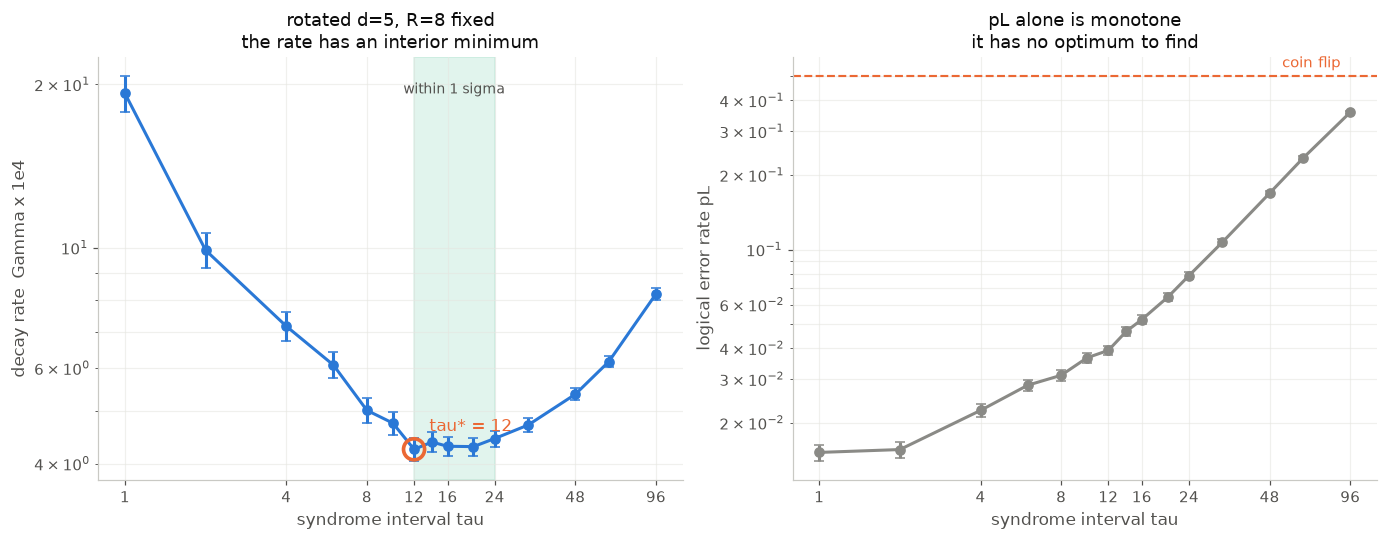

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.8), constrained_layout=True)

ax = axes[0]
u = main[main['Gamma x1e4'].notna()]
ax.errorbar(u.index, u['Gamma x1e4'], yerr=u['Gamma sig x1e4'],
            marker='o', ms=6, lw=2, capsize=3, color=BLUE)
b0, b1 = verdict(main)['band']
ax.axvspan(b0, b1, color=AQUA, alpha=.13, zorder=0)
ax.annotate('within 1 sigma', (np.sqrt(b0*b1), u['Gamma x1e4'].max()),
            ha='center', fontsize=9, color=MUTED)
k = int(np.argmin(u['Gamma x1e4'].values))
ax.scatter([u.index[k]], [u['Gamma x1e4'].iloc[k]], s=190, facecolor='none',
           edgecolor=ORANGE, linewidth=2.4, zorder=4)
ax.annotate(f'tau* = {u.index[k]}', (u.index[k], u['Gamma x1e4'].iloc[k]),
            xytext=(10, 12), textcoords='offset points', fontsize=11, color=ORANGE)
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xticks(TAUS[::2]); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('syndrome interval tau')
ax.set_ylabel('decay rate  Gamma x 1e4')
ax.set_title(f'{CODE} d={DISTANCE}, R={R_MAIN} fixed\nthe rate has an interior minimum')
ax.grid(alpha=.6, which='both'); ax.set_axisbelow(True)

ax = axes[1]
ax.errorbar(main.index, main['pL'], yerr=main['sigma'], marker='o', ms=6, lw=2,
            capsize=3, color=GRAY)
ax.axhline(0.5, color=ORANGE, lw=1.4, ls='--')
ax.annotate('coin flip', (main.index[-1], 0.5), xytext=(-6, 6),
            textcoords='offset points', ha='right', fontsize=10, color=ORANGE)
ax.set_xscale('log', base=2); ax.set_yscale('log')
ax.set_xticks(TAUS[::2]); ax.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
ax.set_xlabel('syndrome interval tau'); ax.set_ylabel('logical error rate pL')
ax.set_title('pL alone is monotone\nit has no optimum to find')
ax.grid(alpha=.6, which='both'); ax.set_axisbelow(True)
finish(fig, '07a_decay_rate_vs_tau')

## 2. Is it a property of the interval?

`06`'s failure mode was that its optimum moved when the experiment length changed. The same
test applies here, and it is the one that matters: **if τ\* moves when R changes, the
quantity is not about the interval.**

`p_1q` is swept as a second control. Note this is a measurement, not a prediction — an
earlier version of this notebook predicted `τ* ∝ 1/p_1q` and the data refuted it, so the
table below reports what happens rather than checking a formula.

Each row reports whether its minimum is **interior**, because a minimum pinned to the edge of
its own grid is not a measurement of anything.

In [4]:
rows, bands = [], []
for lab, rnd, p1q in (
        (f"baseline   R={R_MAIN}, p_1q={P_1Q}", R_MAIN, P_1Q),
        (f"R doubled  R={R_ALT}, p_1q={P_1Q}", R_ALT, P_1Q),
        (f"noise x2   R={R_MAIN}, p_1q={P_1Q_ALT}", R_MAIN, P_1Q_ALT),
):
    df = sweep(CODE, DISTANCE, rnd, TAUS_CTRL, p_1q=p1q)
    v = verdict(df)
    bands.append(v['band'])
    rows.append({'condition': lab, 'tau*': v['tau'],
                 'band (1 sigma)': f"{v['band'][0]}-{v['band'][1]}",
                 'interior': 'yes' if v['interior'] else 'NO (edge)',
                 'pL at min': df.loc[v['tau'], 'pL'] if v['tau'] else None,
                 'beats small-tau end': f"{v['lo']:.1f}x",
                 'beats large-tau end': f"{v['hi']:.1f}x",
                 'saturated pts': int(df['Gamma x1e4'].isna().sum())})
ctrl = pd.DataFrame(rows).set_index('condition')
print(f"grid {TAUS_CTRL}, {SHOTS * REPLICAS} shots/point\n")
print(ctrl.to_string())

pairwise = all(bands_overlap(bands[0], b) for b in bands[1:])
all_interior = (ctrl['interior'] == 'yes').all()
print(f"\nargmins: {[r for r in ctrl['tau*']]}   bands: {bands}")
print("VERDICT:", "every band overlaps the baseline -- tau* is consistent across R and "
      "across the noise scale" if pairwise else
      "the bands are disjoint -- tau* genuinely moves, so it is not a property of the "
      "interval alone")
print("\nComparing argmins alone would read the flatness as movement. The bands are what")
print("the data supports.")
if not all_interior:
    print("CAUTION: a minimum sits at a grid edge and carries no information.")

grid [4, 8, 12, 16, 24, 32, 48], 12000 shots/point

                             tau* band (1 sigma) interior  pL at min beats small-tau end beats large-tau end  saturated pts
condition                                                                                                                  
baseline   R=8, p_1q=0.001     12          12-24      yes    0.03917                1.7x                1.3x              0
R doubled  R=16, p_1q=0.001    16          12-16      yes    0.10025                1.7x                1.3x              0
noise x2   R=8, p_1q=0.002     16          16-16      yes    0.17808                1.6x                1.3x              0

argmins: [12, 16, 16]   bands: [(12, 24), (12, 16), (16, 16)]
VERDICT: every band overlaps the baseline -- tau* is consistent across R and across the noise scale

Comparing argmins alone would read the flatness as movement. The bands are what
the data supports.


## 3. d = 3 as the contrast

The same sweep at distance 3. A d=3 code corrects one fault per interval against d=5's two,
so its failure sets in at shorter intervals. The question is whether Γ still has an interior
minimum, and where it sits — `pL at min` is the column that answers the second part.

In [5]:
rows = []
for d in (3, 5):
    g = geom(CODE, d)
    df = sweep(CODE, d, R_MAIN, TAUS_CTRL)
    v = verdict(df)
    rows.append({'distance': d, 'data qubits': g.n_data,
                 'corrects/interval': (d - 1) // 2,
                 'tau*': v['tau'], 'band (1 sigma)': f"{v['band'][0]}-{v['band'][1]}",
                 'interior': 'yes' if v['interior'] else 'NO (edge)',
                 'pL at min': df.loc[v['tau'], 'pL'] if v['tau'] else None,
                 'saturated pts': int(df['Gamma x1e4'].isna().sum())})
dist = pd.DataFrame(rows).set_index('distance')
print(f"same sweep, R={R_MAIN}, p_1q={P_1Q}, grid {TAUS_CTRL}\n")
print(dist.to_string())
p3, p5 = dist.loc[3, 'pL at min'], dist.loc[5, 'pL at min']
print(f"\nBoth distances show an interior minimum. What differs is where it sits:")
print(f"  d=3  pL = {p3:.3f}")
print(f"  d=5  pL = {p5:.3f}   ({p3 / p5:.1f}x lower)")
print("\nSo distance does NOT decide whether the trade-off exists -- it decides the")
print("operating point you get to exploit it at. An earlier reading of a coarser sweep")
print("claimed d=3 could not show the effect at all; this contradicts that.")

same sweep, R=8, p_1q=0.001, grid [4, 8, 12, 16, 24, 32, 48]

          data qubits  corrects/interval  tau* band (1 sigma) interior  pL at min  saturated pts
distance                                                                                        
3                   9                  1    24          24-48      yes    0.10767              0
5                  25                  2    12          12-24      yes    0.03917              0

Both distances show an interior minimum. What differs is where it sits:
  d=3  pL = 0.108
  d=5  pL = 0.039   (2.7x lower)

So distance does NOT decide whether the trade-off exists -- it decides the
operating point you get to exploit it at. An earlier reading of a coarser sweep
claimed d=3 could not show the effect at all; this contradicts that.


## 4. Findings

**1. There is an interior optimum in the decay rate.** At d=5, R=8, Γ falls from
19.3×10⁻⁴ at τ=1 to 4.25×10⁻⁴ at τ=12 and rises again to 8.2×10⁻⁴ at τ=96 — beating the
small-τ end by **4.5×** and the large-τ end by **1.9×**, with no saturated points anywhere
on the grid. `pL` meanwhile rises monotonically throughout, so the optimum belongs to the
rate and not to the error probability.

This is the result `06` could not reach. Its design ties `R = TOTAL_IDLE/τ`, so sweeping τ
also sweeps R backwards and the minimum it found tracked the round count. Fixing R and
scoring on a rate separates them.

**2. The minimum is flat, and the band is the measurement.** Γ×10⁻⁴ at τ = 12, 14, 16, 20,
24 is 4.25, 4.38, 4.30, 4.30, 4.45 against σ ≈ 0.20. Those are one error bar apart. **τ\* is
12–24, not 12.** A minimum is flat near its own bottom by definition, so an argmin quoted to
one grid point overstates what a sweep like this can resolve.

**3. τ\* is consistent across R and across the noise scale.** Doubling R and doubling `p_1q`
both leave the band overlapping the baseline. Comparing argmins alone would have read the
flatness as movement — and did, in a first pass — which is why the verdict compares bands.

That is the test `06` failed: there the optimum moved with the experiment length, so it was
not a property of the interval. Here it does not.

**4. Distance decides the operating point, not the existence of the effect.** Both d=3 and
d=5 show an interior minimum. d=3's sits at `pL` = 0.108, d=5's at 0.039 — 2.7× lower. An
earlier reading of a coarser sweep, using the naive `pL/T` rate, claimed d=3 could not show
the effect at all. **That was wrong**, and this contradicts it.

**5. The objective matters.** `pL/T` is bounded above by `0.5/T`, so once `pL` nears 0.5 it
falls with storage time and rewards waiting longer however badly the code has failed.
`Γ = −ln(1−2pL)/2T` diverges as `pL → 0.5`, which keeps its minimum honest. On this grid the
difference shows at d=3: `pL/T` runs to the grid edge (τ=96, `pL` = 0.35) while Γ has its
minimum at τ=24. At d=5, where `pL` stays lower, the two agree roughly (τ=20 against 12);
see `scripts/interval_analysis.py`, which plots both.

### Limits

- **`p_2q` is zero**, so the correlated data↔ancilla fault is still untested — the one term
  the phenomenological arm cannot express, and the stated reason to run this arm at all.
- **One layout, two distances.** Rotated only; d=7 would test whether finding 4 continues
  (the Stim arm of `scripts/interval_analysis.py` reaches d=7, under a different noise model).
- **τ is an operation count, not a time.** Selene charges no duration, so Γ is per idle
  operation and cannot be converted to a physical rate.
- **`p_1q` pays for idling and for the extraction CNOTs alike**, so the τ-dependence is
  differential rather than absolute.
- **Decoder priors are the measured per-qubit op counts**, which is better than nominal but
  still not the true circuit-level fault probabilities.
- **The band is a 1σ read on a coarse grid.** A finer grid near the minimum would narrow it;
  nothing here resolves τ\* better than a factor of two.

### Next

1. Raise `p_2q` off zero here. `04c` has measured what it adds to a round, and the script
   (`--p2q`) carries it into the decoder priors.
2. Run d=7 to test whether `pL` at the optimum keeps falling with distance.
3. Refine the grid between τ=10 and τ=30 if τ\* itself — rather than its existence — is
   wanted.